In [148]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [149]:
cell_df = pd.read_csv('/content/sample_data/cell_samples.csv')

In [ ]:
cell_df.head()
cell_df.dtypes
cell_df.shape
cell_df['Class'].value_counts()

In [ ]:
#Distribution of class
benign_df = cell_df[cell_df['Class']==2][0:200]
malignant_df = cell_df[cell_df['Class']==4][0:200]

#help(benign_df.plot())

axes = benign_df.plot(kind='scatter', x='Clump', y='UnifSize', color='blue', label='Benign')
malignant_df.plot(kind='scatter', x='Clump', y='UnifSize', color='red', label='Malignant', ax=axes)

In [ ]:
#Identify unwanted rows
cell_df.isnull().sum()
cell_df['BareNuc'].value_counts()
cell_df = cell_df[pd.to_numeric(cell_df['BareNuc'], errors='coerce').notnull()]
cell_df['BareNuc'] = cell_df['BareNuc'].astype('int')
cell_df.dtypes

In [168]:
#Remove unwanted colums
cell_df.columns

#Independent variables
X = cell_df.drop(['ID','Class'],axis=1)

#Dependent Variables
y = cell_df['Class']

In [ ]:
#Split data into test and training
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.30, random_state=10)

#Resetting the index
X_train = X_train.reset_index(drop='index')
X_test = X_test.reset_index(drop='index')
y_train = y_train.reset_index(drop='index')
y_test = y_test.reset_index(drop='index')

In [178]:
#SVM modeling
from sklearn import svm
clf = svm.SVC(kernel='linear', gamma='auto', C=2)

clf.fit(X_train,y_train)

pred_train = clf.predict(X_train)
pred_test = clf.predict(X_test)

from sklearn.metrics import accuracy_score
accuracy_train = accuracy_score(pred_train,y_train)
accuracy_test = accuracy_score(pred_test,y_test)

from sklearn.metrics import classification_report
print(classification_report(pred_train, y_train))

pd.crosstab(y_train,pd.Series(pred_train),rownames=['ACTUAL'],colnames=['PRED'])
pd.crosstab(y_test,pd.Series(pred_test),rownames=['ACTUAL'],colnames=['PRED'])


PRED,2,4
ACTUAL,,
2,128,3
4,1,73


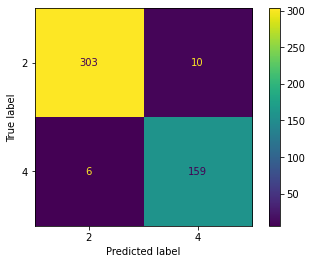

In [131]:
metrics.plot_confusion_matrix(clf, X_train,y_train,values_format='d')
metrics.precision_score(y_test, y_pred=pred_test,average='macro')
metrics.recall_score(np.array(y_test),np.array(pred_test))

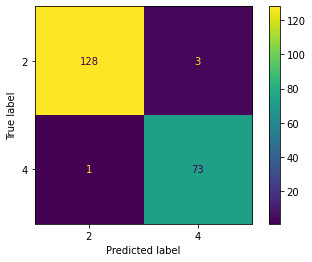

In [132]:
metrics.plot_confusion_matrix(clf, X_test,y_test,values_format='d')

In [128]:
pd.crosstab(y_train,pd.Series(pred_train),rownames=['ACTUAL'],colnames=['PRED'])
pd.crosstab(y_test,pd.Series(pred_test),rownames=['ACTUAL'],colnames=['PRED'])

224    4
586    4
500    2
128    4
267    4
      ..
383    2
334    4
542    2
127    2
273    4
Name: Class, Length: 478, dtype: int64

In [127]:
tt = pd.Series(pred_train)

0      4
1      4
2      2
3      4
4      4
      ..
473    2
474    4
475    2
476    2
477    2
Length: 478, dtype: int64

In [ ]:
import requests
import json
display = requests.get("https://api.coingecko.com/api/v3/coins/markets?vs_currency=USD&order=market_cap_d")
display.status_code
import pandas as pd
from time import sleep
def get_cyrpto_rates(base_currency ='dollar', assets='btc'):
  url='https://api.coingecko.com/api/v3/coins/markets?vs_currency=USD&order=market_cap_d'

response = requests.get(url='https://api.coingecko.com/api/v3/coins/markets?vs_currency=USD&order=market_cap_d')
data=response.json()

print(data)

crypto_currency,crypto_price,crypto_timestap =[],[],[]

for asset in data:
    print(asset)
